Forecasted Housing Prices for the next 10 months:
         Date  Scaled_Predicted_Price  Actual_Predicted_Price_USD
0  2021-02-28                0.856544               242873.640625
1  2021-03-31                0.868374               244100.703125
2  2021-04-30                0.885790               245907.312500
3  2021-05-31                0.905168               247917.343750
4  2021-06-30                0.929917               250484.593750
5  2021-07-31                0.943584               251902.281250
6  2021-08-31                0.954904               253076.437500
7  2021-09-30                0.965297               254154.562500
8  2021-10-31                0.968719               254509.500000
9  2021-11-30                0.973543               255009.921875
10 2021-12-31                0.977250               255394.437500


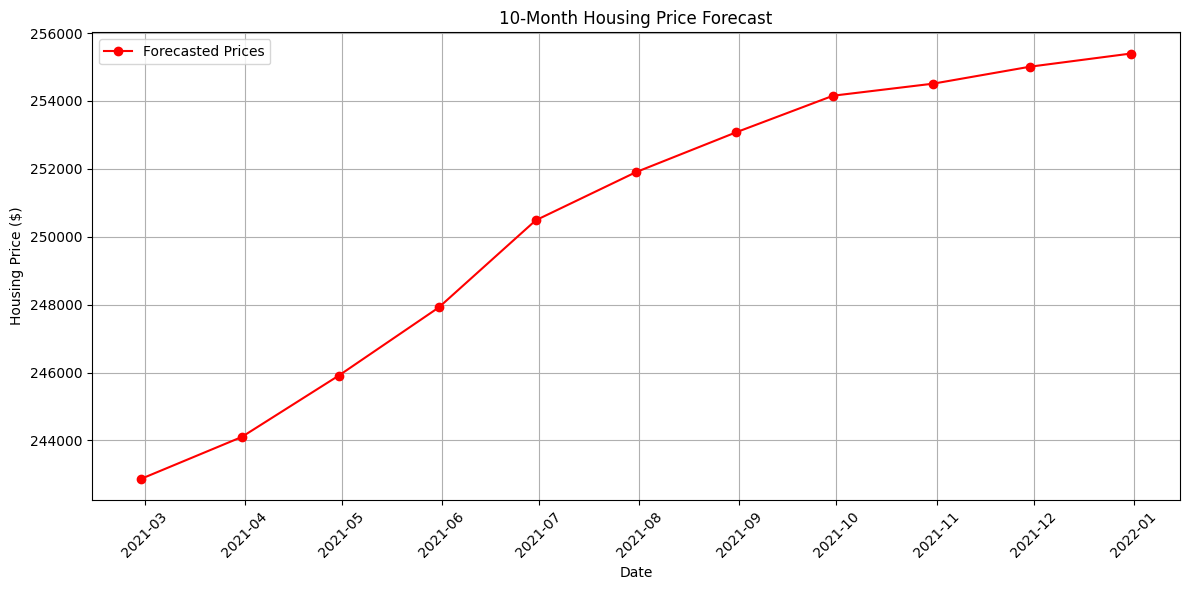

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.models import load_model

# Load your trained model
model = load_model('house_price_lstm_model.keras')

# Load your most recent data
df = pd.read_csv('../data/processed/scaled_data.csv', index_col=0, parse_dates=True)

# Get the latest sequence for prediction
seq_length = 12
feature_cols = [col for col in df.columns if col != 'AvgHousePrice']

# Get the last available sequence
last_sequence = df[feature_cols].iloc[-seq_length:].values
last_sequence = last_sequence.reshape(1, seq_length, len(feature_cols))

# Define the 10-month forecast period
forecast_months = 11
scaled_predictions = []

# Get the latest date in your dataset to start forecasting from
last_date = df.index[-1]
future_dates = pd.date_range(start=last_date, periods=forecast_months+1, freq='ME')[1:]

# Make predictions for the next 10 months
current_batch = last_sequence.copy()

for i in range(forecast_months):
    # Predict next month's price
    next_pred = model.predict(current_batch, verbose=0)[0][0]
    scaled_predictions.append(next_pred)
    
    # Update the sequence for next prediction
    next_seq = current_batch[0, 1:, :].copy()
    
    # Create a new row for the latest prediction
    new_row = next_seq[-1].copy()
    
    # Update the appropriate feature with the new prediction
    # Assuming first feature is the lagged price (adjust index if needed)
    new_row[0] = next_pred
    
    # Add the new row to create the next input batch
    current_batch = np.vstack([next_seq, new_row.reshape(1, -1)])
    current_batch = current_batch.reshape(1, seq_length, len(feature_cols))

# Since we don't have access to the original scaler used during training,
# we need to manually compute the inverse transformation

# OPTION 1: If you know the original min/max values before scaling:
# Define the original min and max values used during scaling
original_min = 154024.15  # Replace with your actual min house price
original_max = 257754.29  # Replace with your actual max house price

# Manually inverse transform the predictions
actual_price_predictions = []
for scaled_val in scaled_predictions:
    # MinMaxScaler formula: X' = (X - min) / (max - min)
    # Inverse: X = X' * (max - min) + min
    actual_price = scaled_val * (original_max - original_min) + original_min
    actual_price_predictions.append(actual_price)

# OPTION 2: If you have a known reference point:
# For example, if you know that a scaled value of 0.5 corresponds to $350,000
# reference_scaled = 0.5
# reference_actual = 350000
# scaling_factor = reference_actual / reference_scaled
# actual_price_predictions = [scaled * scaling_factor for scaled in scaled_predictions]

# Create a dataframe with the results
forecast_df = pd.DataFrame({
    'Date': future_dates,
    'Scaled_Predicted_Price': scaled_predictions,
    'Actual_Predicted_Price_USD': actual_price_predictions
})

# Print the forecasted values
print("Forecasted Housing Prices for the next 10 months:")
print(forecast_df)

# Plot the predictions with actual dollar values
plt.figure(figsize=(12, 6))
plt.plot(forecast_df['Date'], forecast_df['Actual_Predicted_Price_USD'], 'r-o', label='Forecasted Prices')
plt.title('10-Month Housing Price Forecast')
plt.xlabel('Date')
plt.ylabel('Housing Price ($)')
plt.grid(True)
plt.legend()
plt.xticks(rotation=45)
plt.ticklabel_format(style='plain', axis='y')  # Prevent scientific notation
plt.tight_layout()
plt.show()